In [1]:
import os

project_name = "co_elimination_project"
project_dir = os.path.expanduser(f"~/{project_name}")

dirs = [
    "data", "raw_data", "genomes", "alignments",
    "orthologs", "analysis", "results", "logs",
    "notebooks", "src"
]

for d in dirs:
    os.makedirs(os.path.join(project_dir, d), exist_ok=True)

print(f"Project directory created: {project_dir}")

Project directory created: /home/millert/co_elimination_project


In [2]:
!python -m pip install --upgrade pip
!python -m pip install numpy pandas scipy scikit-learn matplotlib seaborn jupyter notebook ipykernel biopython pyyaml requests tqdm pyfaidx ete3 networkx

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [3]:
from pathlib import Path

project_name = "co_elimination_project"
project_dir = Path.home() / project_name

project_dir.mkdir(exist_ok=True)

readme = """# co_elimination_project

Comparative genomics project for coordinated gene co-elimination / phenotype-agnostic pathway discovery.

## Directory layout
- data/            : project data
- raw_data/        : raw input files
- genomes/         : genome FASTA files
- alignments/      : multiple sequence alignments
- orthologs/       : ortholog mapping outputs
- analysis/        : intermediate analysis outputs
- results/         : final tables, figures, summaries
- logs/            : log files
- notebooks/       : notebooks for exploration
- src/             : analysis scripts
"""

(project_dir / "README.md").write_text(readme)

config = """project_name: co_elimination_project
data_dir: ./data
raw_data_dir: ./raw_data
genome_dir: ./genomes
alignment_dir: ./alignments
ortholog_dir: ./orthologs
analysis_dir: ./analysis
results_dir: ./results
logs_dir: ./logs
"""

(project_dir / "config.yaml").write_text(config)

print(f"Project directory created at: {project_dir}")

Project directory created at: /home/millert/co_elimination_project


In [4]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib
import requests

# Project location
project_dir = Path.home() / "co_elimination_project"

# Required project folders
project_dirs = [
    "data",
    "raw_data",
    "genomes",
    "alignments",
    "orthologs",
    "analysis",
    "results",
    "logs",
    "notebooks",
    "src",
]

for directory in project_dirs:
    (project_dir / directory).mkdir(parents=True, exist_ok=True)

# Check core Python packages
required_packages = [
    "numpy",
    "pandas",
    "scipy",
    "sklearn",
    "Bio",
    "yaml",
    "requests",
]

package_status = {}

for package_name in required_packages:
    try:
        importlib.import_module(package_name)
        package_status[package_name] = "OK"
    except ImportError:
        package_status[package_name] = "MISSING"

print("Package status:")
for package_name, status in package_status.items():
    print(f"  {package_name}: {status}")

# Official source pages
sources = {
    "zoonomia_data_page": "https://zoonomiaproject.org/the-data/",
    "zoonomia_alignment_page": "https://cglgenomics.ucsc.edu/data/cactus/",
    "toga_download_index": "https://genome.senckenberg.de/download/TOGA/",
    "toga_repository": "https://github.com/hillerlab/TOGA2",
}

source_dir = project_dir / "raw_data" / "source_inventory"
source_dir.mkdir(parents=True, exist_ok=True)

manifest_rows = []

for source_name, url in sources.items():
    output_file = source_dir / f"{source_name}.html"

    try:
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        content = response.content
        output_file.write_bytes(content)

        sha256 = hashlib.sha256(content).hexdigest()

        manifest_rows.append(
            {
                "source_name": source_name,
                "url": url,
                "local_file": str(output_file.relative_to(project_dir)),
                "status": response.status_code,
                "bytes": len(content),
                "sha256": sha256,
            }
        )

        print(f"Downloaded: {source_name} ({len(content):,} bytes)")

    except Exception as error:
        manifest_rows.append(
            {
                "source_name": source_name,
                "url": url,
                "local_file": "",
                "status": f"ERROR: {error}",
                "bytes": 0,
                "sha256": "",
            }
        )

        print(f"FAILED: {source_name}")
        print(f"  {error}")

# Save a reproducibility manifest
import pandas as pd

manifest = pd.DataFrame(manifest_rows)
manifest["checked_at_utc"] = datetime.now(timezone.utc).isoformat()

manifest_path = project_dir / "raw_data" / "source_inventory_manifest.tsv"
manifest.to_csv(manifest_path, sep="\t", index=False)

print()
print(f"Project directory: {project_dir}")
print(f"Manifest saved to: {manifest_path}")
print("Metadata inventory complete.")

Package status:
  numpy: OK
  pandas: OK
  scipy: OK
  sklearn: OK
  Bio: OK
  yaml: OK
  requests: OK
FAILED: zoonomia_data_page
  403 Client Error: Forbidden for url: https://zoonomiaproject.org/the-data/
FAILED: zoonomia_alignment_page
  ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))
Downloaded: toga_download_index (4,205 bytes)
Downloaded: toga_repository (341,228 bytes)

Project directory: /home/millert/co_elimination_project
Manifest saved to: /home/millert/co_elimination_project/raw_data/source_inventory_manifest.tsv
Metadata inventory complete.


In [5]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib
import time
import requests

project_dir = Path.home() / "co_elimination_project"

source_dir = project_dir / "raw_data" / "source_inventory"
source_dir.mkdir(parents=True, exist_ok=True)

# Browser-like headers help with public websites that reject basic Python requests.
headers = {
    "User-Agent": (
        "Mozilla/5.0 (X11; Linux x86_64) "
        "AppleWebKit/537.36 Chrome/120 Safari/537.36"
    ),
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.9",
    "Referer": "https://www.google.com/",
}

# Try alternate official URLs when a server blocks one form.
sources = {
    "zoonomia_data_page": [
        "https://zoonomiaproject.org/the-data/",
        "https://zoonomiaproject.org/the-data",
        "https://zoonomiaproject.org/",
    ],
    "zoonomia_alignment_page": [
        "https://cglgenomics.ucsc.edu/data/cactus/",
        "http://cglgenomics.ucsc.edu/data/cactus/",
    ],
    "toga_download_index": [
        "https://genome.senckenberg.de/download/TOGA/",
        "http://genome.senckenberg.de/download/TOGA/",
    ],
    "toga_repository": [
        "https://github.com/hillerlab/TOGA2",
    ],
}

# Confirm that the core environment is available.
required_packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "scipy": "scipy",
    "scikit-learn": "sklearn",
    "biopython": "Bio",
    "pyyaml": "yaml",
    "requests": "requests",
}

print("Checking Python packages:")
for display_name, import_name in required_packages.items():
    try:
        importlib.import_module(import_name)
        print(f"  OK      {display_name}")
    except ImportError:
        print(f"  MISSING {display_name}")

session = requests.Session()
session.headers.update(headers)

manifest_rows = []

for source_name, candidate_urls in sources.items():
    output_file = source_dir / f"{source_name}.html"
    success = False

    for url in candidate_urls:
        try:
            print(f"\nTrying {source_name}: {url}")

            response = session.get(
                url,
                timeout=(20, 90),
                allow_redirects=True,
            )

            # Do not accidentally save a large genome/alignment file.
            content_length = int(response.headers.get("content-length", "0") or 0)

            if content_length > 50_000_000:
                raise RuntimeError(
                    f"response is too large for metadata check: "
                    f"{content_length:,} bytes"
                )

            response.raise_for_status()
            content = response.content

            if len(content) > 50_000_000:
                raise RuntimeError(
                    f"downloaded response is too large: {len(content):,} bytes"
                )

            output_file.write_bytes(content)
            checksum = hashlib.sha256(content).hexdigest()

            manifest_rows.append(
                {
                    "source_name": source_name,
                    "url": response.url,
                    "status": response.status_code,
                    "bytes": len(content),
                    "local_file": str(output_file.relative_to(project_dir)),
                    "sha256": checksum,
                    "error": "",
                }
            )

            print(f"SUCCESS: {len(content):,} bytes")
            success = True
            break

        except Exception as error:
            print(f"FAILED: {error}")
            time.sleep(2)

    if not success:
        manifest_rows.append(
            {
                "source_name": source_name,
                "url": "",
                "status": "FAILED",
                "bytes": 0,
                "local_file": "",
                "sha256": "",
                "error": "All candidate URLs failed",
            }
        )

# Save the results.
import pandas as pd

manifest = pd.DataFrame(manifest_rows)
manifest["checked_at_utc"] = datetime.now(timezone.utc).isoformat()

manifest_path = project_dir / "raw_data" / "source_inventory_manifest.tsv"
manifest.to_csv(manifest_path, sep="\t", index=False)

print("\nInventory complete.")
print(f"Manifest: {manifest_path}")
print("\nSuccessful downloads:")
print(manifest[manifest["status"] == 200][["source_name", "bytes"]].to_string(index=False))

print("\nFailed downloads:")
print(manifest[manifest["status"] != 200][["source_name", "error"]].to_string(index=False))

Checking Python packages:
  OK      numpy
  OK      pandas
  OK      scipy
  OK      scikit-learn
  OK      biopython
  OK      pyyaml
  OK      requests

Trying zoonomia_data_page: https://zoonomiaproject.org/the-data/
SUCCESS: 148,700 bytes

Trying zoonomia_alignment_page: https://cglgenomics.ucsc.edu/data/cactus/
SUCCESS: 226,407 bytes

Trying toga_download_index: https://genome.senckenberg.de/download/TOGA/
SUCCESS: 4,205 bytes

Trying toga_repository: https://github.com/hillerlab/TOGA2
SUCCESS: 341,255 bytes

Inventory complete.
Manifest: /home/millert/co_elimination_project/raw_data/source_inventory_manifest.tsv

Successful downloads:
            source_name  bytes
     zoonomia_data_page 148700
zoonomia_alignment_page 226407
    toga_download_index   4205
        toga_repository 341255

Failed downloads:
Empty DataFrame
Columns: [source_name, error]
Index: []


In [6]:
from pathlib import Path
from datetime import datetime, timezone
from html.parser import HTMLParser
from urllib.parse import urljoin
import pandas as pd
import requests

project_dir = Path.home() / "co_elimination_project"
inventory_dir = project_dir / "raw_data" / "toga_inventory"
inventory_dir.mkdir(parents=True, exist_ok=True)

headers = {
    "User-Agent": (
        "Mozilla/5.0 (X11; Linux x86_64) "
        "AppleWebKit/537.36 Chrome/120 Safari/537.36"
    )
}

class LinkParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.links = []

    def handle_starttag(self, tag, attrs):
        if tag == "a":
            attributes = dict(attrs)
            href = attributes.get("href")
            if href:
                self.links.append(href)

session = requests.Session()
session.headers.update(headers)

base_url = "https://genome.senckenberg.de/download/TOGA/"

# Small documentation files only.
documentation_urls = {
    "README.txt": urljoin(base_url, "README.txt"),
    "README.download.txt": urljoin(base_url, "README.download.txt"),
    "README.multipleCodonAlignments.txt": urljoin(
        base_url,
        "README.multipleCodonAlignments.txt",
    ),
}

for filename, url in documentation_urls.items():
    response = session.get(url, timeout=(20, 90))
    response.raise_for_status()
    output_path = inventory_dir / filename
    output_path.write_bytes(response.content)
    print(f"Saved {filename}: {len(response.content):,} bytes")

# Inventory the main archive and selected reference directories.
directory_urls = {
    "main": base_url,
    "human_reference": urljoin(base_url, "human_hg38_reference/"),
    "mouse_reference": urljoin(base_url, "mouse_mm10_reference/"),
}

inventory_rows = []

for directory_name, directory_url in directory_urls.items():
    response = session.get(directory_url, timeout=(20, 90))
    response.raise_for_status()

    parser = LinkParser()
    parser.feed(response.text)

    for href in sorted(set(parser.links)):
        if href in {"../", "/", "#"}:
            continue

        file_url = urljoin(directory_url, href)
        filename = href.rstrip("/").split("/")[-1]

        lower_name = filename.lower()
        likely_relevant = any(
            keyword in lower_name
            for keyword in [
                "loss",
                "ortholog",
                "annotation",
                "gtf",
                "bed",
                "codon",
                "gene",
                "isoform",
                "mutation",
            ]
        )

        inventory_rows.append(
            {
                "directory": directory_name,
                "name": filename,
                "url": file_url,
                "is_directory": href.endswith("/"),
                "likely_relevant": likely_relevant,
            }
        )

inventory = pd.DataFrame(inventory_rows)
inventory["checked_at_utc"] = datetime.now(timezone.utc).isoformat()

inventory_path = inventory_dir / "toga_available_files.tsv"
inventory.to_csv(inventory_path, sep="\t", index=False)

print()
print(f"TOGA inventory saved to: {inventory_path}")
print(f"Total listed entries: {len(inventory):,}")

print("\nLikely relevant entries:")
relevant = inventory[inventory["likely_relevant"]]
print(
    relevant[
        ["directory", "name", "url", "is_directory"]
    ].to_string(index=False)
)

Saved README.txt: 10,717 bytes
Saved README.download.txt: 465 bytes
Saved README.multipleCodonAlignments.txt: 2,063 bytes

TOGA inventory saved to: /home/millert/co_elimination_project/raw_data/toga_inventory/toga_available_files.tsv
Total listed entries: 72

Likely relevant entries:
      directory                               name                                                                                       url  is_directory
           main                   BatAnnotationEVM                             https://genome.senckenberg.de/download/TOGA/BatAnnotationEVM/          True
           main README.multipleCodonAlignments.txt            https://genome.senckenberg.de/download/TOGA/README.multipleCodonAlignments.txt         False
human_reference            MultipleCodonAlignments https://genome.senckenberg.de/download/TOGA/human_hg38_reference/MultipleCodonAlignments/          True


In [7]:
import os
import sys

PROJECT_ROOT = "/home/millert/co_elimination_project"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

os.chdir(PROJECT_ROOT)

from src.validation_gate import validation_status, print_validation_gate

print(validation_status("source_inventory"))
print_validation_gate("source_inventory")

{'status': 'source-validated', 'scientific_conclusion_ready': False, 'message': 'Public sources and metadata have been checked and recorded.'}

=== VALIDATION GATE ===
Current stage: source_inventory
Status: source-validated
Scientific conclusion ready: False
Public sources and metadata have been checked and recorded.

Checklist:
1. Exact source URL or data version is identified
2. Command or script that produced the output is recorded
3. Output file exists and the schema is inspected
4. Sample sanity check or positive control is passed
5. Interpretation is qualified; no final biological claim without evidence
6. Independent validation or wet-lab evidence is required for final conclusions


In [8]:
import os
import sys

PROJECT_ROOT = "/home/millert/co_elimination_project"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

os.chdir(PROJECT_ROOT)

from src.validation_gate import validation_status, print_validation_gate

print(validation_status("source_inventory"))
print_validation_gate("source_inventory")

{'status': 'source-validated', 'scientific_conclusion_ready': False, 'message': 'Public sources and metadata have been checked and recorded.'}

=== VALIDATION GATE ===
Current stage: source_inventory
Status: source-validated
Scientific conclusion ready: False
Public sources and metadata have been checked and recorded.

Checklist:
1. Exact source URL or data version is identified
2. Command or script that produced the output is recorded
3. Output file exists and the schema is inspected
4. Sample sanity check or positive control is passed
5. Interpretation is qualified; no final biological claim without evidence
6. Independent validation or wet-lab evidence is required for final conclusions


In [9]:
%cd /home/millert/co_elimination_project
!bash run_species_match.sh
!python3 src/export_assembly_review.py

/home/millert/co_elimination_project
Running from: /home/millert/co_elimination_project
drwxr-xr-x 2 millert g-millert 4096 Oct  8 12:37 analysis
drwxr-xr-x 2 millert g-millert 4096 Sep 20 13:16 logs
drwxr-xr-x 6 millert g-millert 4096 Oct  8 12:32 raw_data
drwxr-xr-x 8 millert g-millert 4096 Oct 10 21:45 results
Project root OK


/home/millert/.local/lib/python3.9/site-packages/IPython/core/magics/osm.py:417: UserWarning: using dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


Excluded species rows: 78
excluded_alternative_assembly_only: 62
excluded_exact_assembly_not_in_toga: 7
excluded_unverified_assembly_source: 9
Review table: /home/millert/co_elimination_project/results/zoonomia_toga_assembly_review.tsv


In [10]:
!python3 src/export_assembly_review.py

Excluded species rows: 78
excluded_alternative_assembly_only: 62
excluded_exact_assembly_not_in_toga: 7
excluded_unverified_assembly_source: 9
Review table: /home/millert/co_elimination_project/results/zoonomia_toga_assembly_review.tsv


In [11]:
!bash -lc 'bash run_species_match.sh; echo EXIT:$?'

Running from: /home/millert/co_elimination_project
drwxr-xr-x 2 millert g-millert 4096 Oct  8 12:37 analysis
drwxr-xr-x 2 millert g-millert 4096 Sep 20 13:16 logs
drwxr-xr-x 6 millert g-millert 4096 Oct  8 12:32 raw_data
drwxr-xr-x 8 millert g-millert 4096 Oct 10 21:45 results
Project root OK
EXIT:0


In [12]:
!ls -l /home/millert/co_elimination_project
!find /home/millert/co_elimination_project -maxdepth 3 -type f | sort

total 124
drwxr-xr-x 2 millert g-millert  4096 Sep 20 13:16 alignments
drwxr-xr-x 2 millert g-millert  4096 Oct  8 12:37 analysis
-rw-r--r-- 1 millert g-millert   220 Oct 12 14:41 config.yaml
drwxr-xr-x 2 millert g-millert  4096 Sep 20 13:16 data
drwxr-xr-x 2 millert g-millert  4096 Sep 20 13:16 genomes
-rw-r--r-- 1 millert g-millert 10400 Oct 10 22:05 LITERATURE_REVIEW.md
drwxr-xr-x 2 millert g-millert  4096 Sep 20 13:16 logs
drwxr-xr-x 2 millert g-millert  4096 Sep 20 17:24 notebooks
drwxr-xr-x 2 millert g-millert  4096 Oct  8 12:28 orthologs
-rw-r--r-- 1 millert g-millert  2456 Sep 20 17:31 PROGRESS_2026-09-20.md
-rw-r--r-- 1 millert g-millert  3112 Oct 10 21:30 PROGRESS_2026_10_10.md
-rw-r--r-- 1 millert g-millert  4422 Sep 24 16:25 PROJECT_GOAL.md
-rw-r--r-- 1 millert g-millert  2274 Oct 10 20:34 PROJECT_RATIONALE_AND_NOVELTY.md
-rw-r--r-- 1 millert g-millert  2432 Oct 10 21:45 QUALITY_CONTROL_SUMMARY.md
drwxr-xr-x 6 millert g-millert  4096 Oct  8 12:32 raw_data
-rw-r--r-- 1 mille

In [13]:
!bash -lc 'bash run_species_match.sh >/tmp/run_species_match.log 2>&1; echo EXIT:$?; tail -n 50 /tmp/run_species_match.log'

EXIT:0
Running from: /home/millert/co_elimination_project
drwxr-xr-x 2 millert g-millert 4096 Oct  8 12:37 analysis
drwxr-xr-x 2 millert g-millert 4096 Sep 20 13:16 logs
drwxr-xr-x 6 millert g-millert 4096 Oct  8 12:32 raw_data
drwxr-xr-x 8 millert g-millert 4096 Oct 10 21:45 results
Project root OK


In [14]:
import requests
import pandas as pd

ids = ["ENSG00000203811", "ENSG00000203852"]

def ensembl_lookup(ids):
    payload = {
        "ids": ids,
        "attributes": "ensembl_gene_id,external_gene_name,description",
        "format": "json"
    }
    r = requests.post("https://rest.ensembl.org/lookup/id", json=payload, headers={"Content-Type":"application/json"})
    r.raise_for_status()
    return r.json()

print(ensembl_lookup(ids))

{'ENSG00000203852': {'id': 'ENSG00000203852', 'db_type': 'core', 'species': 'homo_sapiens', 'version': 4, 'object_type': 'Gene'}, 'ENSG00000203811': {'db_type': 'core', 'id': 'ENSG00000203811', 'version': 2, 'object_type': 'Gene', 'species': 'homo_sapiens'}}


In [15]:
import pandas as pd
import requests
from pathlib import Path

project_dir = Path("/home/millert/co_elimination_project")
cand_in = project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv"
cand_out = project_dir / "results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv"

df = pd.read_csv(cand_in, sep="\t")

ids = sorted(set(df["gene_a"].dropna()) | set(df["gene_b"].dropna()))
lookup = {}

# Ensembl API accepts batches; use chunks to avoid limit issues
for i in range(0, len(ids), 100):
    batch = ids[i:i + 100]
    payload = {
        "ids": batch,
        "attributes": "ensembl_gene_id,external_gene_name,description",
        "format": "json",
    }
    r = requests.post(
        "https://rest.ensembl.org/lookup/id",
        json=payload,
        headers={"Content-Type": "application/json"},
    )
    r.raise_for_status()
    data = r.json()

    for gene_id, info in data.items():
        if isinstance(info, dict):
            name = info.get("external_name") or info.get("external_gene_name") or ""
            desc = info.get("description") or ""
        else:
            name = ""
            desc = ""
        lookup[gene_id] = {"gene_name": name, "description": desc}

def gene_name(gid):
    return lookup.get(gid, {}).get("gene_name", "")

def gene_desc(gid):
    return lookup.get(gid, {}).get("description", "")

df["gene_a_symbol"] = df["gene_a"].map(gene_name)
df["gene_a_description"] = df["gene_a"].map(gene_desc)
df["gene_b_symbol"] = df["gene_b"].map(gene_name)
df["gene_b_description"] = df["gene_b"].map(gene_desc)

# optional: keep only top candidates
df = df.sort_values(["q_bh_within_selected_shortlist", "enrichment_naive"], ascending=[True, False])

df.to_csv(cand_out, sep="\t", index=False)

print(f"Mapped candidate file written to: {cand_out}")
print(df.head(20)[[
    "gene_a", "gene_a_symbol", "gene_b", "gene_b_symbol",
    "shared_loss_count", "enrichment_naive", "q_bh_within_selected_shortlist"
]].to_string(index=False))

KeyError: 'q_bh_within_selected_shortlist'

In [ ]:
import pandas as pd
import requests
from pathlib import Path
import time

project_dir = Path("/home/millert/co_elimination_project")
cand_in = project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv"
cand_out = project_dir / "results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv"

df = pd.read_csv(cand_in, sep="\t")

ids = sorted(set(df["gene_a"].dropna()) | set(df["gene_b"].dropna()))
lookup = {}

session = requests.Session()
session.headers.update({"Content-Type": "application/json"})

for i in range(0, len(ids), 100):
    batch = ids[i:i + 100]
    payload = {
        "ids": batch,
        "attributes": "ensembl_gene_id,external_gene_name,description",
        "format": "json"
    }

    for attempt in range(5):
        try:
            r = session.post(
                "https://rest.ensembl.org/lookup/id",
                json=payload,
                timeout=30
            )
            r.raise_for_status()
            data = r.json()
            break
        except Exception as e:
            if attempt < 4:
                time.sleep(2 ** attempt)
                continue
            raise

    for gene_id, info in data.items():
        if not isinstance(info, dict):
            continue
        name = (
            info.get("external_name")
            or info.get("external_gene_name")
            or info.get("display_name")
            or ""
        )
        desc = info.get("description") or ""
        lookup[gene_id] = {"gene_name": name, "description": desc}

def gene_name(gid):
    return lookup.get(gid, {}).get("gene_name", "")

def gene_desc(gid):
    return lookup.get(gid, {}).get("description", "")

df["gene_a_symbol"] = df["gene_a"].map(gene_name)
df["gene_a_description"] = df["gene_a"].map(gene_desc)
df["gene_b_symbol"] = df["gene_b"].map(gene_name)
df["gene_b_description"] = df["gene_b"].map(gene_desc)

df = df.sort_values(["q_bh_within_selected_shortlist", "enrichment_naive"], ascending=[True, False])

df.to_csv(cand_out, sep="\t", index=False)

print(f"Saved: {cand_out}")
print(df.head(20)[[
    "gene_a", "gene_a_symbol", "gene_b", "gene_b_symbol",
    "shared_loss_count", "enrichment_naive", "q_bh_within_selected_shortlist"
]].to_string(index=False))

KeyError: 'q_bh_within_selected_shortlist'

In [ ]:
import pandas as pd
import requests
from pathlib import Path
import time

project_dir = Path("/home/millert/co_elimination_project")
cand_in = project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv"
cand_out = project_dir / "results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv"

df = pd.read_csv(cand_in, sep="\t")

ids = sorted(set(df["gene_a"].dropna()) | set(df["gene_b"].dropna()))
lookup = {}

session = requests.Session()
session.headers.update({
    "Content-Type": "application/json",
    "User-Agent": "Mozilla/5.0"
})

for i in range(0, len(ids), 100):
    batch = ids[i:i+100]
    payload = {
        "ids": batch,
        "attributes": "ensembl_gene_id,external_gene_name,description",
        "format": "json"
    }

    for attempt in range(8):
        try:
            r = session.post(
                "https://rest.ensembl.org/lookup/id",
                json=payload,
                timeout=60
            )
            if r.status_code == 429:
                time.sleep(5 * (attempt + 1))
                continue
            r.raise_for_status()
            data = r.json()
            break
        except Exception as e:
            if attempt < 7:
                time.sleep(2 ** attempt)
                continue
            raise

    if not isinstance(data, dict):
        continue

    for gene_id, info in data.items():
        if not isinstance(info, dict):
            continue
        name = (
            info.get("external_name")
            or info.get("external_gene_name")
            or info.get("display_name")
            or ""
        )
        desc = info.get("description") or ""
        lookup[gene_id] = {"gene_name": name, "description": desc}

def gene_name(gid):
    return lookup.get(gid, {}).get("gene_name", "")

def gene_desc(gid):
    return lookup.get(gid, {}).get("description", "")

df["gene_a_symbol"] = df["gene_a"].map(gene_name)
df["gene_a_description"] = df["gene_a"].map(gene_desc)
df["gene_b_symbol"] = df["gene_b"].map(gene_name)
df["gene_b_description"] = df["gene_b"].map(gene_desc)

df = df.sort_values(["q_bh_within_selected_shortlist", "enrichment_naive"], ascending=[True, False])
df.to_csv(cand_out, sep="\t", index=False)

print(df.head(20)[[
    "gene_a", "gene_a_symbol", "gene_b", "gene_b_symbol",
    "shared_loss_count", "enrichment_naive", "q_bh_within_selected_shortlist"
]].to_string(index=False))

KeyError: 'q_bh_within_selected_shortlist'

In [ ]:
import pandas as pd
import requests
import time
from pathlib import Path

project_dir = Path("/home/millert/co_elimination_project")
cand_in = project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv"
cand_out = project_dir / "results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv"

df = pd.read_csv(cand_in, sep="\t")

ids = sorted(set(df["gene_a"].dropna().astype(str)) | set(df["gene_b"].dropna().astype(str)))
lookup = {}

session = requests.Session()
session.headers.update({
    "Content-Type": "application/json",
    "User-Agent": "Mozilla/5.0",
    "Accept": "application/json"
})

def fetch_batch(batch):
    for attempt in range(10):
        try:
            r = session.post(
                "https://rest.ensembl.org/lookup/id",
                json={
                    "ids": batch,
                    "attributes": "ensembl_gene_id,external_gene_name,description",
                    "format": "json"
                },
                timeout=60
            )
            if r.status_code == 429:
                time.sleep(5 * (attempt + 1))
                continue
            if r.status_code >= 500:
                time.sleep(3 * (attempt + 1))
                continue
            r.raise_for_status()
            return r.json()
        except Exception:
            time.sleep(2 ** attempt)
    return {}

for i in range(0, len(ids), 50):
    batch = ids[i:i + 50]
    data = fetch_batch(batch)
    if not isinstance(data, dict):
        continue
    for gene_id, info in data.items():
        if not isinstance(info, dict):
            continue
        lookup[str(gene_id)] = {
            "gene_name": (
                info.get("external_name")
                or info.get("external_gene_name")
                or info.get("display_name")
                or ""
            ),
            "description": info.get("description") or ""
        }

def gene_name(gid):
    return lookup.get(str(gid), {}).get("gene_name", "")

def gene_desc(gid):
    return lookup.get(str(gid), {}).get("description", "")

df["gene_a_symbol"] = df["gene_a"].map(gene_name)
df["gene_a_description"] = df["gene_a"].map(gene_desc)
df["gene_b_symbol"] = df["gene_b"].map(gene_name)
df["gene_b_description"] = df["gene_b"].map(gene_desc)

df = df.sort_values(["q_bh_within_selected_shortlist", "enrichment_naive"], ascending=[True, False])
df.to_csv(cand_out, sep="\t", index=False)

print(df.head(20)[[
    "gene_a", "gene_a_symbol", "gene_b", "gene_b_symbol",
    "shared_loss_count", "enrichment_naive", "q_bh_within_selected_shortlist"
]].to_string(index=False))
print(f"\nSaved: {cand_out}")

KeyError: 'q_bh_within_selected_shortlist'

In [ ]:
import pandas as pd
import requests
import time
from pathlib import Path

project_dir = Path("/home/millert/co_elimination_project")
cand_in = project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv"
cand_out = project_dir / "results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv"

df = pd.read_csv(cand_in, sep="\t")

ids = sorted(set(df["gene_a"].dropna().astype(str)) | set(df["gene_b"].dropna().astype(str)))
lookup = {}

session = requests.Session()
session.headers.update({
    "Content-Type": "application/json",
    "User-Agent": "Mozilla/5.0",
    "Accept": "application/json"
})

def fetch_batch(batch):
    for attempt in range(12):
        try:
            r = session.post(
                "https://rest.ensembl.org/lookup/id",
                json={
                    "ids": batch,
                    "attributes": "ensembl_gene_id,external_gene_name,description",
                    "format": "json"
                },
                timeout=(15, 90)
            )
            if r.status_code == 429:
                print(f"429 rate limit for batch {batch[:3]}... retry {attempt+1}/12")
                time.sleep(10 * (attempt + 1))
                continue
            if r.status_code >= 500:
                print(f"Server error {r.status_code} for batch {batch[:3]}... retry {attempt+1}/12")
                time.sleep(5 * (attempt + 1))
                continue
            if r.status_code in (400, 403):
                print(f"Blocked request: {r.status_code} - {r.text[:300]}")
                return {}
            r.raise_for_status()
            return r.json()
        except Exception as e:
            print(f"Request error: {e} | retry {attempt+1}/12")
            time.sleep(2 ** attempt)
    return {}

# batch in small chunks to avoid rate limiting
for i in range(0, len(ids), 25):
    batch = ids[i:i+25]
    data = fetch_batch(batch)
    if not isinstance(data, dict):
        continue
    for gene_id, info in data.items():
        if not isinstance(info, dict):
            continue
        lookup[str(gene_id)] = {
            "gene_name": (
                info.get("external_name")
                or info.get("external_gene_name")
                or info.get("display_name")
                or ""
            ),
            "description": info.get("description") or ""
        }

def gene_name(gid):
    return lookup.get(str(gid), {}).get("gene_name", "")

def gene_desc(gid):
    return lookup.get(str(gid), {}).get("description", "")

df["gene_a_symbol"] = df["gene_a"].map(gene_name)
df["gene_a_description"] = df["gene_a"].map(gene_desc)
df["gene_b_symbol"] = df["gene_b"].map(gene_name)
df["gene_b_description"] = df["gene_b"].map(gene_desc)

df = df.sort_values(["q_bh_within_selected_shortlist", "enrichment_naive"], ascending=[True, False])
df.to_csv(cand_out, sep="\t", index=False)

print(df.head(20)[[
    "gene_a", "gene_a_symbol", "gene_b", "gene_b_symbol",
    "shared_loss_count", "enrichment_naive", "q_bh_within_selected_shortlist"
]].to_string(index=False))
print(f"\nSaved: {cand_out}")

KeyError: 'q_bh_within_selected_shortlist'

In [ ]:
import requests
r = requests.get("https://rest.ensembl.org/info?content-type=application/json")
print(r.status_code)
print(r.text[:300])

404
{"error":"page not found. Please check your uri and refer to our documentation https://rest.ensembl.org/"}


In [16]:
from src.validation_gate import validation_status, print_validation_gate
print_validation_gate("source_inventory")


=== VALIDATION GATE ===
Current stage: source_inventory
Status: source-validated
Scientific conclusion ready: False
Public sources and metadata have been checked and recorded.

Checklist:
1. Exact source URL or data version is identified
2. Command or script that produced the output is recorded
3. Output file exists and the schema is inspected
4. Sample sanity check or positive control is passed
5. Interpretation is qualified; no final biological claim without evidence
6. Independent validation or wet-lab evidence is required for final conclusions


In [17]:
from pathlib import Path

project_dir = Path("/home/millert/co_elimination_project")

# look for matrix-like outputs from the pipeline
for pattern in ["analysis/**/*.tsv", "analysis/**/*.csv", "orthologs/**/*.tsv", "data/**/*.tsv"]:
    for f in sorted(project_dir.glob(pattern)):
        print(f, f.stat().st_size)

/home/millert/co_elimination_project/analysis/gene_status_matrix.tsv 7182220
/home/millert/co_elimination_project/orthologs/zoonomia_toga_assembly_manifest.tsv 75079
/home/millert/co_elimination_project/orthologs/zoonomia_toga_eligible_assemblies.tsv 51479
/home/millert/co_elimination_project/orthologs/zoonomia_toga_file_availability.tsv 94143


In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

matrix_path = Path("/home/millert/co_elimination_project/analysis/YOUR_MATRIX_FILE.tsv")  # adjust after finding it
mat = pd.read_csv(matrix_path, sep="\t", index_col=0)

# encode TOGA statuses as numbers for coloring
status_map = {"intact": 0, "partial": 1, "inactivated": 2, "missing": 3,
              "retained": 0, "lost": 2}
num = mat.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(3)

plt.figure(figsize=(max(8, num.shape[1] * 0.4), max(6, num.shape[0] * 0.3)))
sns.heatmap(
    num,
    cmap=sns.color_palette(["#2166ac", "#92c5de", "#f4a582", "#b2182b"]),
    cbar_kws={"ticks": [0, 1, 2, 3]},
)
cbar = plt.gcf().axes[-1]
cbar.set_yticklabels(["intact", "partial", "inactivated", "missing"])
plt.xlabel("Gene")
plt.ylabel("Species")
plt.title("Gene status across species (TOGA classification)")
plt.tight_layout()
out = Path("/home/millert/co_elimination_project/results/gene_status_heatmap.png")
plt.savefig(out, dpi=200)
print(f"Saved: {out}")

FileNotFoundError: [Errno 2] No such file or directory: '/home/millert/co_elimination_project/analysis/YOUR_MATRIX_FILE.tsv'

In [19]:
import pandas as pd

mat = pd.read_csv(
    "/home/millert/co_elimination_project/analysis/gene_status_matrix.tsv",
    sep="\t",
    index_col=0,
    nrows=5,
)
print(mat.shape)
print(mat.columns[:10].tolist())
print(mat.iloc[:5, :6])
print(pd.unique(mat.values.ravel())[:20])

(5, 162)
['Acomys_cahirinus', 'Allactaga_bullata', 'Alouatta_palliata', 'Ammotragus_lervia', 'Anoura_caudifer', 'Aplodontia_rufa', 'Artibeus_jamaicensis', 'Ateles_geoffroyi', 'Balaenoptera_acutorostrata', 'Balaenoptera_bonaerensis']
                Acomys_cahirinus Allactaga_bullata Alouatta_palliata  \
gene_id                                                                
ENSG00000000003                I                 I                 I   
ENSG00000000005                I                 I                 I   
ENSG00000000419                I                 I                 I   
ENSG00000000457                I                 I                 I   
ENSG00000000460                I                 I                PI   

                Ammotragus_lervia Anoura_caudifer Aplodontia_rufa  
gene_id                                                            
ENSG00000000003                 I               I              PI  
ENSG00000000005                 I               I         

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path("/home/millert/co_elimination_project")

mat = pd.read_csv(project_dir / "analysis/gene_status_matrix.tsv", sep="\t", index_col=0)
cand = pd.read_csv(project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv", sep="\t")

# restrict to candidate genes so the plot stays readable
genes = sorted(set(cand["gene_a"].astype(str)) | set(cand["gene_b"].astype(str)))
genes = [g for g in genes if g in mat.columns]
sub = mat[genes]
print(f"Matrix subset: {sub.shape[0]} species × {sub.shape[1]} candidate genes")

# encode statuses as numbers — adjust keys if Step 1 shows different labels
status_map = {
    "intact": 0, "retained": 0, "I": 0,
    "partial": 1, "partially_intact": 1, "PI": 1,
    "inactivated": 2, "lost": 2, "L": 2, "UL": 2,
    "missing": 3, "M": 3,
}
num = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(3)

unmapped = set(pd.unique(sub.values.ravel())) - set(status_map)
if unmapped:
    print("WARNING unmapped status labels (shown as 'missing'):", unmapped)

plt.figure(figsize=(max(10, num.shape[1] * 0.35), max(6, num.shape[0] * 0.3)))
ax = sns.heatmap(
    num,
    cmap=sns.color_palette(["#2166ac", "#92c5de", "#f4a582", "#b2182b"]),
    cbar_kws={"ticks": [0, 1, 2, 3]},
    linewidths=0,
)
cbar = ax.collections[0].colorbar
cbar.set_ticklabels(["intact/retained", "partial", "inactivated/lost", "missing"])
plt.xlabel("Candidate gene")
plt.ylabel("Species")
plt.title("TOGA gene status across species — co-loss candidates")
plt.tight_layout()

out = project_dir / "results/gene_status_heatmap.png"
plt.savefig(out, dpi=200)
print(f"Saved: {out}")

Matrix subset: 19464 species × 0 candidate genes


ValueError: zero-size array to reduction operation fmin which has no identity

Error in callback <function _draw_all_if_interactive at 0x149562ad33a0> (for post_execute), with arguments args (),kwargs {}:


ValueError: Image size of 1000x583920 pixels is too large. It must be less than 2^16 in each direction.

<Figure size 1000x583920 with 0 Axes>

Matrix subset: 162 species × 90 candidate genes
WARNING unmapped status labels (shown as 'missing'): {'PG'}


/tmp/ipykernel_4186949/3656397455.py:26: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(3)


Saved: /home/millert/co_elimination_project/results/gene_status_heatmap.png


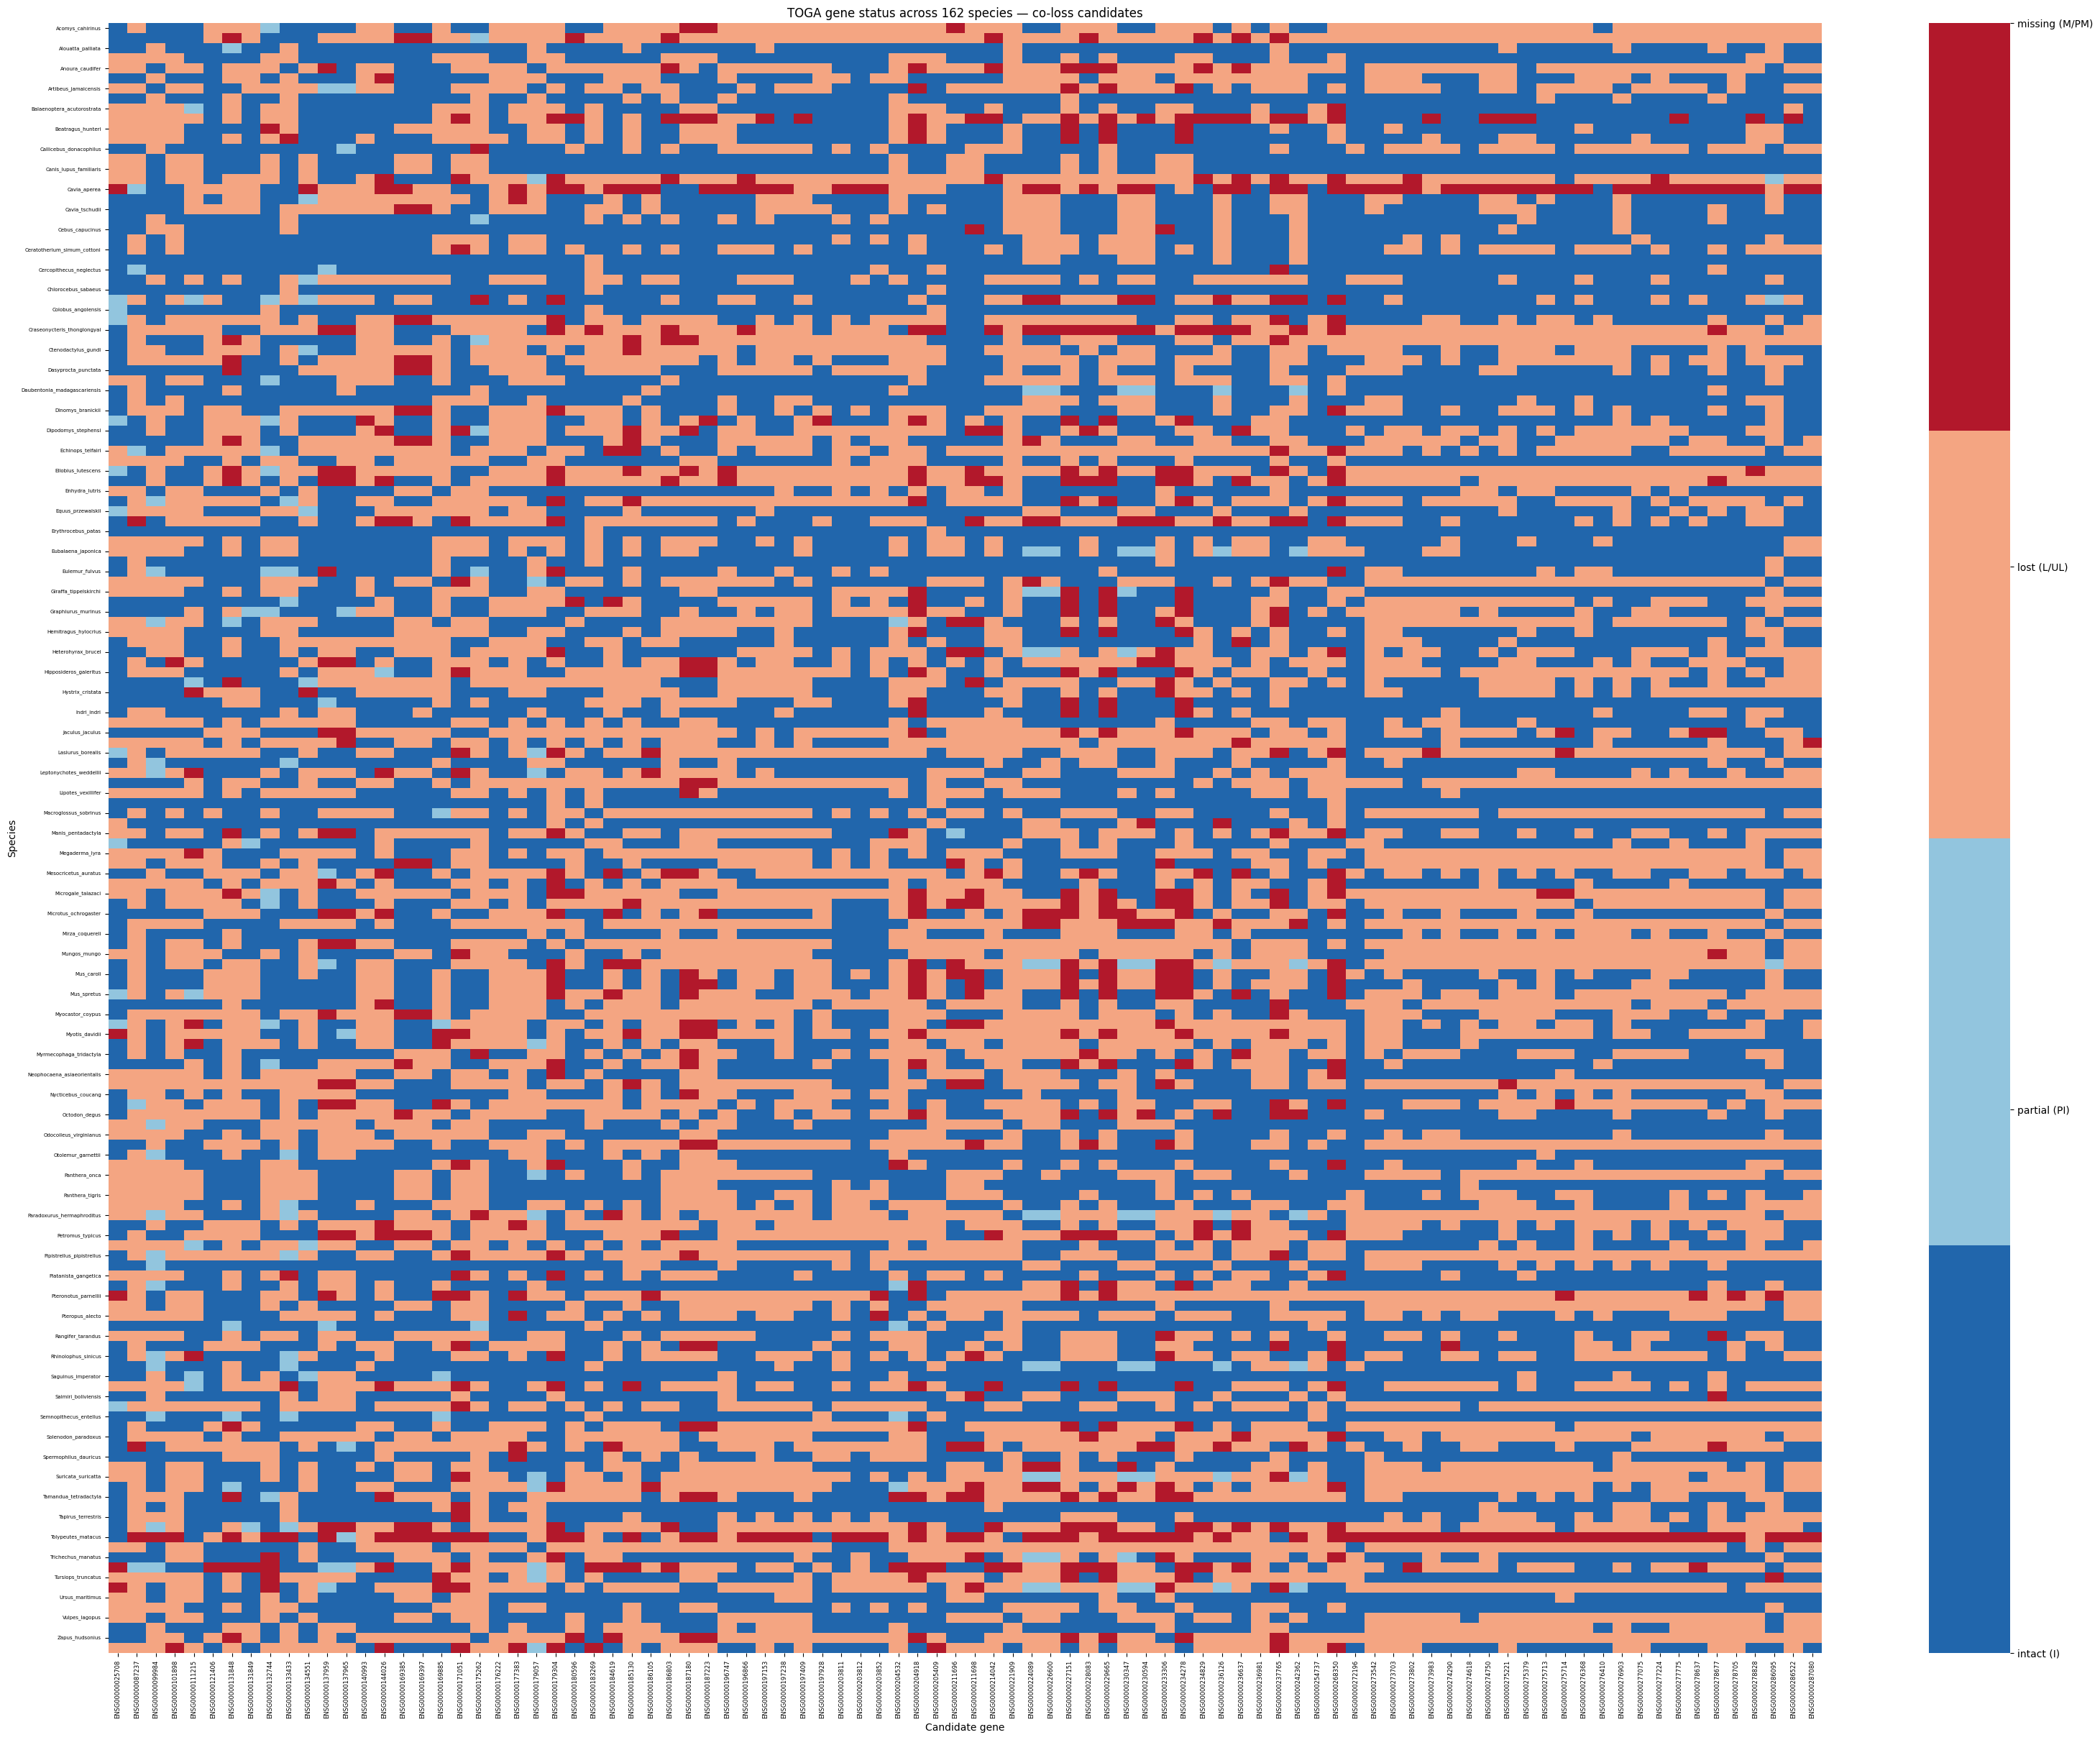

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path("/home/millert/co_elimination_project")

mat = pd.read_csv(project_dir / "analysis/gene_status_matrix.tsv", sep="\t", index_col=0)
cand = pd.read_csv(project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv", sep="\t")

# genes are ROWS in this matrix (index), species are COLUMNS
genes = sorted(set(cand["gene_a"].astype(str)) | set(cand["gene_b"].astype(str)))
genes = [g for g in genes if g in mat.index]
sub = mat.loc[genes].T  # transpose: rows = species, columns = genes
print(f"Matrix subset: {sub.shape[0]} species × {sub.shape[1]} candidate genes")

# actual TOGA labels from Step 1 output
status_map = {
    "I": 0,   # intact
    "PI": 1,  # partially intact
    "UL": 2,  # uncertain lost
    "L": 2,   # lost
    "PM": 3,  # partially missing
    "M": 3,   # missing
}
num = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(3)

unmapped = set(pd.unique(sub.values.ravel())) - set(status_map)
if unmapped:
    print("WARNING unmapped status labels (shown as 'missing'):", unmapped)

plt.figure(figsize=(max(10, num.shape[1] * 0.35), max(6, num.shape[0] * 0.15)))
ax = sns.heatmap(
    num,
    cmap=sns.color_palette(["#2166ac", "#92c5de", "#f4a582", "#b2182b"]),
    cbar_kws={"ticks": [0, 1, 2, 3]},
    linewidths=0,
)
cbar = ax.collections[0].colorbar
cbar.set_ticklabels(["intact (I)", "partial (PI)", "lost (L/UL)", "missing (M/PM)"])
plt.xlabel("Candidate gene")
plt.ylabel("Species")
plt.title("TOGA gene status across 162 species — co-loss candidates")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(fontsize=5)
plt.tight_layout()

out = project_dir / "results/gene_status_heatmap.png"
plt.savefig(out, dpi=200)
print(f"Saved: {out}")

Matrix subset: 162 species × 90 candidate genes
WARNING unmapped status labels (shown as 'missing'): {'PG'}


/tmp/ipykernel_4186949/3656397455.py:26: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(3)


Saved: /home/millert/co_elimination_project/results/gene_status_heatmap.png


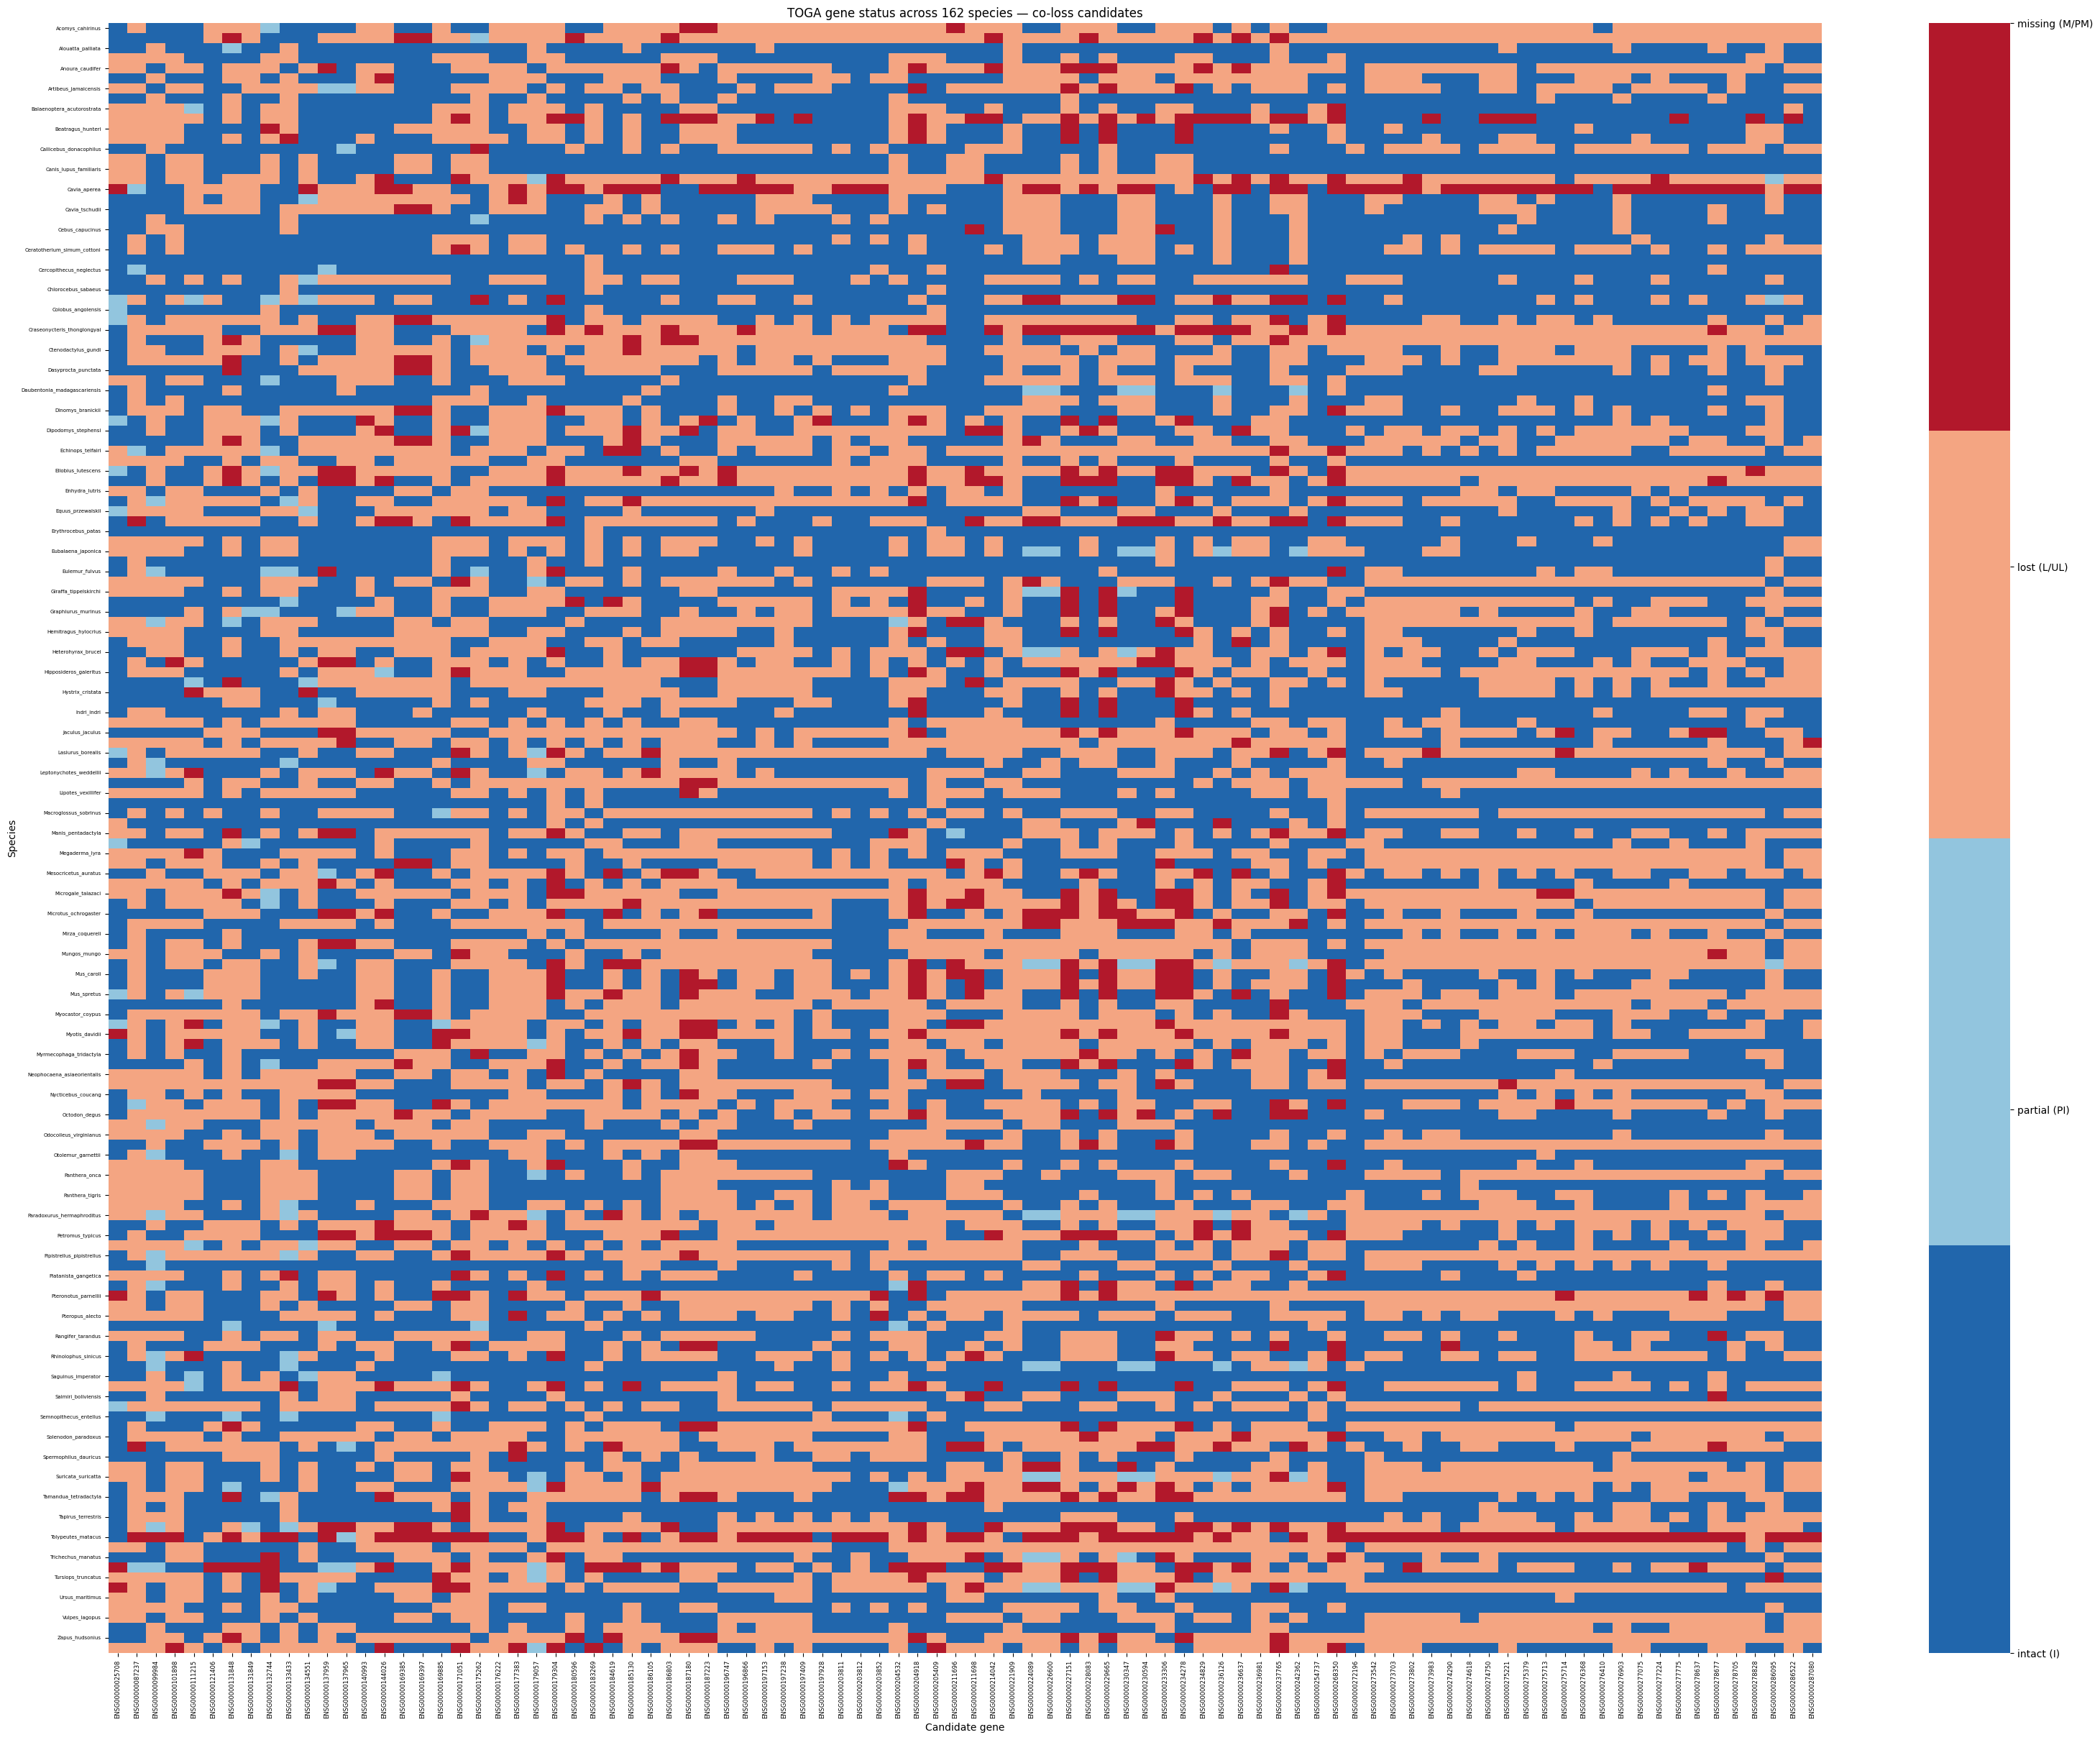

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

project_dir = Path("/home/millert/co_elimination_project")

mat = pd.read_csv(project_dir / "analysis/gene_status_matrix.tsv", sep="\t", index_col=0)
cand = pd.read_csv(project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv", sep="\t")

# genes are ROWS in this matrix (index), species are COLUMNS
genes = sorted(set(cand["gene_a"].astype(str)) | set(cand["gene_b"].astype(str)))
genes = [g for g in genes if g in mat.index]
sub = mat.loc[genes].T  # transpose: rows = species, columns = genes
print(f"Matrix subset: {sub.shape[0]} species × {sub.shape[1]} candidate genes")

# actual TOGA labels from Step 1 output
status_map = {
    "I": 0,   # intact
    "PI": 1,  # partially intact
    "UL": 2,  # uncertain lost
    "L": 2,   # lost
    "PM": 3,  # partially missing
    "M": 3,   # missing
}
num = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(3)

unmapped = set(pd.unique(sub.values.ravel())) - set(status_map)
if unmapped:
    print("WARNING unmapped status labels (shown as 'missing'):", unmapped)

plt.figure(figsize=(max(10, num.shape[1] * 0.35), max(6, num.shape[0] * 0.15)))
ax = sns.heatmap(
    num,
    cmap=sns.color_palette(["#2166ac", "#92c5de", "#f4a582", "#b2182b"]),
    cbar_kws={"ticks": [0, 1, 2, 3]},
    linewidths=0,
)
cbar = ax.collections[0].colorbar
cbar.set_ticklabels(["intact (I)", "partial (PI)", "lost (L/UL)", "missing (M/PM)"])
plt.xlabel("Candidate gene")
plt.ylabel("Species")
plt.title("TOGA gene status across 162 species — co-loss candidates")
plt.xticks(rotation=90, fontsize=6)
plt.yticks(fontsize=5)
plt.tight_layout()

out = project_dir / "results/gene_status_heatmap.png"
plt.savefig(out, dpi=200)
print(f"Saved: {out}")

In [23]:
loss_rows = (num >= 2).any(axis=1)
num = num.loc[loss_rows]

In [24]:
import pandas as pd

project_dir = Path("/home/millert/co_elimination_project")

# rebuild the full numeric matrix over candidate genes (all 162 species)
genes = [g for g in dict.fromkeys(
    list(cand["gene_a"].astype(str)) + list(cand["gene_b"].astype(str))
) if g in mat.index]
sub = mat.loc[genes].T  # species × genes

status_map = {"I": 0, "PI": 1, "UL": 2, "PM": 2, "L": 3, "M": 4}
num_all = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(4)

stats = pd.DataFrame({
    "n_intact":    (num_all == 0).sum(),
    "n_partial":   (num_all == 1).sum(),
    "n_uncertain": (num_all == 2).sum(),
    "n_lost":      (num_all == 3).sum(),
    "n_missing":   (num_all == 4).sum(),
})
stats["n_detectable"] = stats[["n_intact", "n_partial", "n_uncertain", "n_lost"]].sum(axis=1)
stats["loss_frac"] = stats["n_lost"] / stats["n_detectable"]
stats["intact_frac"] = stats["n_intact"] / stats["n_detectable"]

# add symbols if the symbolic file exists
sym_file = project_dir / "results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv"
if sym_file.exists():
    sym = pd.read_csv(sym_file, sep="\t")
    name_map = {}
    for ci, cn in [("gene_a", "gene_a_symbol"), ("gene_b", "gene_b_symbol")]:
        for gid, s in zip(sym[ci].astype(str), sym[cn].astype(str)):
            if s and s != "nan":
                name_map.setdefault(gid, s)
    stats.insert(0, "symbol", [name_map.get(g, "") for g in stats.index])

# how often each gene appears in top-ranked pairs (a proxy for "importance")
top = cand.nsmallest(50, "q_bh_within_selected_shortlist")
pair_hits = pd.concat([top["gene_a"], top["gene_b"]]).astype(str).value_counts()
stats["in_top50_pairs"] = stats.index.map(pair_hits).fillna(0).astype(int)

stats = stats.sort_values("loss_frac", ascending=False)
stats.to_csv(project_dir / "results/gene_loss_summary.tsv", sep="\t")

print("=== MOST LOST (highest loss_frac among detectable species) ===")
print(stats.head(20)[["symbol", "n_lost", "n_detectable", "loss_frac", "in_top50_pairs"]].to_string())

print("\n=== MOST CONSERVED (highest intact_frac) ===")
print(stats.sort_values("intact_frac", ascending=False).head(20)[["symbol", "n_intact", "n_detectable", "intact_frac", "in_top50_pairs"]].to_string())

print("\n=== SUSPICIOUS: high loss but also high missing (possible assembly artifact) ===")
sus = stats[(stats["n_missing"] > 20) & (stats["loss_frac"] > 0.3)]
print(sus[["symbol", "n_lost", "n_missing", "loss_frac"]].to_string() if len(sus) else "none")

/tmp/ipykernel_4186949/1367963443.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num_all = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(4)


KeyError: 'q_bh_within_selected_shortlist'

In [25]:
print(cand.columns.tolist())
print(cand.head(3))

['gene_a', 'gene_b', 'shared_loss_count', 'gene_a_loss_count_comparable', 'gene_b_loss_count_comparable', 'expected_shared_loss_count_naive', 'excess_shared_losses_naive', 'jaccard_comparable', 'enrichment_naive', 'comparable_species_count']
            gene_a           gene_b  shared_loss_count  \
0  ENSG00000203811  ENSG00000203852                 62   
1  ENSG00000196866  ENSG00000277224                 63   
2  ENSG00000286522  ENSG00000287080                 61   

   gene_a_loss_count_comparable  gene_b_loss_count_comparable  \
0                            65                            65   
1                            64                            69   
2                            67                            66   

   expected_shared_loss_count_naive  excess_shared_losses_naive  \
0                         26.910828                   35.089172   
1                         29.052632                   33.947368   
2                         28.714286                   32.285714

In [26]:
import pandas as pd

project_dir = Path("/home/millert/co_elimination_project")

# rebuild the full numeric matrix over candidate genes (all 162 species)
genes = [g for g in dict.fromkeys(
    list(cand["gene_a"].astype(str)) + list(cand["gene_b"].astype(str))
) if g in mat.index]
sub = mat.loc[genes].T  # species × genes

status_map = {"I": 0, "PI": 1, "UL": 2, "PM": 2, "L": 3, "M": 4}
num_all = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(4)

stats = pd.DataFrame({
    "n_intact":    (num_all == 0).sum(),
    "n_partial":   (num_all == 1).sum(),
    "n_uncertain": (num_all == 2).sum(),
    "n_lost":      (num_all == 3).sum(),
    "n_missing":   (num_all == 4).sum(),
})
stats["n_detectable"] = stats[["n_intact", "n_partial", "n_uncertain", "n_lost"]].sum(axis=1)
stats["loss_frac"] = stats["n_lost"] / stats["n_detectable"]
stats["intact_frac"] = stats["n_intact"] / stats["n_detectable"]

# add symbols if the symbolic file exists
sym_file = project_dir / "results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv"
if sym_file.exists():
    sym = pd.read_csv(sym_file, sep="\t")
    name_map = {}
    for ci, cn in [("gene_a", "gene_a_symbol"), ("gene_b", "gene_b_symbol")]:
        for gid, s in zip(sym[ci].astype(str), sym[cn].astype(str)):
            if s and s != "nan":
                name_map.setdefault(gid, s)
    stats.insert(0, "symbol", [name_map.get(g, "") for g in stats.index])

# --- robust ranking: use whatever significance/score column actually exists ---
print("cand columns:", cand.columns.tolist())

rank_col = None
ascending = True
for c in cand.columns:
    lc = c.lower()
    if lc.startswith("q") or "fdr" in lc or "adj" in lc:
        rank_col, ascending = c, True    # q-value: smaller is better
        break
    if lc in ("p_value", "pvalue", "p", "pval") or lc.startswith("p_"):
        rank_col, ascending = c, True    # p-value: smaller is better
        break
    if "enrichment" in lc or "score" in lc or "odds" in lc:
        rank_col, ascending = c, False   # enrichment/score: larger is better
        break

if rank_col:
    cand_sorted = cand.sort_values(rank_col, ascending=ascending)
    print(f"Ranking pairs by: {rank_col} ({'smallest' if ascending else 'largest'} first)")
else:
    cand_sorted = cand  # assume file is already in rank order
    print("No ranking column found — using file order")

top = cand_sorted.head(50)
pair_hits = pd.concat([top["gene_a"], top["gene_b"]]).astype(str).value_counts()
stats["in_top50_pairs"] = stats.index.map(pair_hits).fillna(0).astype(int)

stats = stats.sort_values("loss_frac", ascending=False)
stats.to_csv(project_dir / "results/gene_loss_summary.tsv", sep="\t")

cols = [c for c in ["symbol", "n_lost", "n_detectable", "loss_frac", "in_top50_pairs"] if c in stats.columns]
print("\n=== MOST LOST (highest loss_frac among detectable species) ===")
print(stats.head(20)[cols].to_string())

print("\n=== MOST CONSERVED (highest intact_frac) ===")
cols_c = [c for c in ["symbol", "n_intact", "n_detectable", "intact_frac", "in_top50_pairs"] if c in stats.columns]
print(stats.sort_values("intact_frac", ascending=False).head(20)[cols_c].to_string())

print("\n=== SUSPICIOUS: high loss but also high missing (possible assembly artifact) ===")
sus = stats[(stats["n_missing"] > 20) & (stats["loss_frac"] > 0.3)]
sus_cols = [c for c in ["symbol", "n_lost", "n_missing", "loss_frac"] if c in sus.columns]
print(sus[sus_cols].to_string() if len(sus) else "none")

cand columns: ['gene_a', 'gene_b', 'shared_loss_count', 'gene_a_loss_count_comparable', 'gene_b_loss_count_comparable', 'expected_shared_loss_count_naive', 'excess_shared_losses_naive', 'jaccard_comparable', 'enrichment_naive', 'comparable_species_count']
Ranking pairs by: enrichment_naive (largest first)

=== MOST LOST (highest loss_frac among detectable species) ===
                 n_lost  n_detectable  loss_frac  in_top50_pairs
gene_id                                                         
ENSG00000087237     104           159   0.654088               0
ENSG00000196747      93           159   0.584906               0
ENSG00000175262      91           160   0.568750               0
ENSG00000273703      90           160   0.562500               0
ENSG00000237765      74           132   0.560606               0
ENSG00000101898      89           159   0.559748               0
ENSG00000221909      89           161   0.552795               0
ENSG00000177383      83           154   0.53

/tmp/ipykernel_4186949/363737974.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  num_all = sub.replace(status_map).apply(pd.to_numeric, errors="coerce").fillna(4)


In [27]:
gene = stats.index[0]  # top lost gene
row = sub[gene]
lost_in = row[row == "L"].index.tolist()
intact_in = row[row == "I"].index.tolist()
print(f"{gene}: lost in {len(lost_in)} species")
print(lost_in)
print(f"\nintact in {len(intact_in)}:")
print(intact_in)

ENSG00000087237: lost in 104 species
['Acomys_cahirinus', 'Ammotragus_lervia', 'Anoura_caudifer', 'Artibeus_jamaicensis', 'Balaenoptera_acutorostrata', 'Balaenoptera_bonaerensis', 'Beatragus_hunteri', 'Bison_bison', 'Canis_lupus', 'Canis_lupus_familiaris', 'Carollia_perspicillata', 'Ceratotherium_simum', 'Ceratotherium_simum_cottoni', 'Choloepus_didactylus', 'Condylura_cristata', 'Craseonycteris_thonglongyai', 'Cricetomys_gambianus', 'Ctenodactylus_gundi', 'Ctenomys_sociabilis', 'Dasypus_novemcinctus', 'Daubentonia_madagascariensis', 'Dicerorhinus_sumatrensis', 'Dinomys_branickii', 'Elaphurus_davidianus', 'Enhydra_lutris', 'Eptesicus_fuscus', 'Equus_przewalskii', 'Eschrichtius_robustus', 'Eubalaena_japonica', 'Eulemur_flavifrons', 'Eulemur_fulvus', 'Felis_nigripes', 'Giraffa_tippelskirchi', 'Helogale_parvula', 'Hemitragus_hylocrius', 'Hipposideros_armiger', 'Hipposideros_galeritus', 'Indri_indri', 'Inia_geoffrensis', 'Kogia_breviceps', 'Lasiurus_borealis', 'Lemur_catta', 'Leptonychotes

In [28]:
human_rows = [c for c in sub.index if "sapien" in c.lower() or "homo" in c.lower()]
print(human_rows)  # find the exact species label first
print(sub.loc[human_rows, gene] if human_rows else "no human row found")

[]
no human row found


In [29]:
import requests
r = requests.get("https://rest.ensembl.org/lookup/id/ENSG00000087237?content-type=application/json")
info = r.json()
print(info.get("display_name"), "|", info.get("biotype"))

CETP | protein_coding


In [30]:
import gzip
import re
import pandas as pd
import requests
from pathlib import Path

project_dir = Path("/home/millert/co_elimination_project")
ens_dir = project_dir / "raw_data" / "ensembl"
ens_dir.mkdir(parents=True, exist_ok=True)
map_path = ens_dir / "ensembl_id_symbol_map.tsv"

biomart_xml = """<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE Query>
<Query virtualSchemaName="default" formatter="TSV" header="1" uniqueRows="1" count="" datasetConfigVersion="0.6">
  <Dataset name="hsapiens_gene_ensembl" interface="default">
    <Attribute name="ensembl_gene_id" />
    <Attribute name="external_gene_name" />
    <Attribute name="gene_biotype" />
    <Attribute name="description" />
  </Dataset>
</Query>"""

ok = False
for mirror in [
    "https://www.ensembl.org/biomart/martservice",
    "https://useast.ensembl.org/biomart/martservice",
    "https://asia.ensembl.org/biomart/martservice",
]:
    try:
        r = requests.get(mirror, params={"query": biomart_xml}, timeout=(20, 300))
        r.raise_for_status()
        if "gene stable id" not in r.text.splitlines()[0].lower():
            raise RuntimeError(f"unexpected header: {r.text[:200]}")
        map_path.write_text(r.text)
        print(f"BioMart OK via {mirror} -> {map_path} ({len(r.text):,} bytes)")
        ok = True
        break
    except Exception as e:
        print(f"BioMart failed via {mirror}: {e}")

if not ok:
    # Fallback: parse the Ensembl GTF (FTP download, no rate limits)
    listing = requests.get("https://ftp.ensembl.org/pub/current_gtf/homo_sapiens/",
                           timeout=(20, 60)).text
    fname = re.findall(r"Homo_sapiens\.GRCh38\.\d+\.chr\.gtf\.gz", listing)[0]
    gz = ens_dir / fname
    r = requests.get(f"https://ftp.ensembl.org/pub/current_gtf/homo_sapiens/{fname}",
                     timeout=(20, 600))
    r.raise_for_status()
    gz.write_bytes(r.content)

    rows = []
    with gzip.open(gz, "rt") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            f = line.rstrip("\n").split("\t")
            if len(f) < 9 or f[2] != "gene":
                continue
            attrs = dict(re.findall(r'(\S+) "([^"]*)"', f[8]))
            rows.append({
                "Gene stable ID": attrs.get("gene_id", "").split(".")[0],
                "Gene name": attrs.get("gene_name", ""),
                "Gene type": attrs.get("gene_biotype", ""),
                "Description": "",
            })
    pd.DataFrame(rows).to_csv(map_path, sep="\t", index=False)
    print(f"GTF parsed -> {map_path} ({len(rows):,} genes)")

BioMart OK via https://www.ensembl.org/biomart/martservice -> /home/millert/co_elimination_project/raw_data/ensembl/ensembl_id_symbol_map.tsv (7,261,803 bytes)


In [31]:
m = pd.read_csv(map_path, sep="\t", dtype=str).fillna("")
m.columns = [c.strip().lower() for c in m.columns]
m["gene stable id"] = m["gene stable id"].str.split(".").str[0]  # strip version suffixes

name = dict(zip(m["gene stable id"], m["gene name"]))
bio  = dict(zip(m["gene stable id"], m["gene type"]))

cand = pd.read_csv(project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv", sep="\t")

def base(s):
    return s.astype(str).str.split(".").str[0]

cand["gene_a_symbol"]  = base(cand["gene_a"]).map(name).fillna("")
cand["gene_a_biotype"] = base(cand["gene_a"]).map(bio).fillna("")
cand["gene_b_symbol"]  = base(cand["gene_b"]).map(name).fillna("")
cand["gene_b_biotype"] = base(cand["gene_b"]).map(bio).fillna("")

cand_out = project_dir / "results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv"
cand.to_csv(cand_out, sep="\t", index=False)

all_genes = set(base(cand["gene_a"])) | set(base(cand["gene_b"]))
unmapped = [g for g in all_genes if g not in name]
print(f"Saved: {cand_out}")
print(f"Candidate genes: {len(all_genes)}, unmapped: {len(unmapped)}")
if unmapped[:10]:
    print("First unmapped IDs:", unmapped[:10])
print(cand.head(15)[["gene_a", "gene_a_symbol", "gene_b", "gene_b_symbol",
                     "shared_loss_count", "q_bh_within_selected_shortlist"]].to_string(index=False))

Saved: /home/millert/co_elimination_project/results/agentic_triage/ranked_co_loss_candidates_symbolic.tsv
Candidate genes: 90, unmapped: 2
First unmapped IDs: ['ENSG00000272196', 'ENSG00000203812']


KeyError: "['q_bh_within_selected_shortlist'] not in index"

In [32]:
raw = pd.read_csv(project_dir / "results/agentic_triage/ranked_co_loss_candidates.tsv", sep="\t")

ua = set(raw["gene_a"].astype(str))
ub = set(raw["gene_b"].astype(str))
union_raw = ua | ub
union_stripped = {g.split(".")[0] for g in union_raw}

print(f"pairs in file:           {len(raw)}")
print(f"unique gene_a:           {raw['gene_a'].nunique()}")
print(f"unique gene_b:           {raw['gene_b'].nunique()}")
print(f"unique union (raw):      {len(union_raw)}")
print(f"unique union (stripped): {len(union_stripped)}")

# how concentrated are the pairs?
counts = pd.concat([raw["gene_a"], raw["gene_b"]]).astype(str).value_counts()
print("\npair-counts per gene (top 10):")
print(counts.head(10).to_string())

pairs in file:           100
unique gene_a:           62
unique gene_b:           57
unique union (raw):      90
unique union (stripped): 90

pair-counts per gene (top 10):
ENSG00000286522    12
ENSG00000287080     8
ENSG00000186105     6
ENSG00000277775     6
ENSG00000197153     5
ENSG00000274750     5
ENSG00000275713     5
ENSG00000277224     5
ENSG00000273802     4
ENSG00000196866     4


In [33]:
# what are the hub genes?
for gid in ["ENSG00000286522", "ENSG00000287080", "ENSG00000186105"]:
    print(gid, "->", name.get(gid, "(unmapped)"), "|", bio.get(gid, ""))

# and what do the top hub's 12 partners look like?
hub = "ENSG00000286522"
partners = raw.loc[raw["gene_a"] == hub, "gene_b"].tolist() + \
           raw.loc[raw["gene_b"] == hub, "gene_a"].tolist()
for p in partners:
    print(f"  {p} -> {name.get(p.split('.')[0], '(unmapped)')}")

ENSG00000286522 -> H3C2 | protein_coding
ENSG00000287080 -> H3C3 | protein_coding
ENSG00000186105 -> LRRC70 | protein_coding
  ENSG00000287080 -> H3C3
  ENSG00000197153 -> H3C12
  ENSG00000277775 -> H3C7
  ENSG00000278637 -> H4C1
  ENSG00000197409 -> H3C4
  ENSG00000273983 -> H3C8
  ENSG00000276410 -> H2BC3
  ENSG00000275379 -> H3C11
  ENSG00000278705 -> H4C2
  ENSG00000274618 -> H4C6
  ENSG00000275713 -> H2BC9
  ENSG00000274750 -> H3C6


In [34]:
HISTONE_PREFIXES = ("H1", "H2A", "H2B", "H3", "H4")  # matches H2BC3, H3C2, H4C1, ...
def is_histone(sym):
    return isinstance(sym, str) and sym.startswith(HISTONE_PREFIXES)

cand["a_hist"] = base(cand["gene_a"]).map(name).map(is_histone)
cand["b_hist"] = base(cand["gene_b"]).map(name).map(is_histone)

n_hist_pairs = int((cand["a_hist"] & cand["b_hist"]).sum())
n_any_hist   = int((cand["a_hist"] | cand["b_hist"]).sum())
print(f"pairs with BOTH genes histone: {n_hist_pairs}/100")
print(f"pairs with ≥1 histone gene:    {n_any_hist}/100")

# biotype-level summary across the whole shortlist
genes_df = pd.DataFrame({"gid": sorted(all_genes)})
genes_df["symbol"]  = genes_df["gid"].map(name)
genes_df["histone"] = genes_df["symbol"].map(is_histone)
print(f"\nhistone genes among the 90: {int(genes_df['histone'].sum())}/90")

# if you drop histone-histone pairs, does the ranking survive?
core = cand[~(cand["a_hist"] & cand["b_hist"])].copy()
print(f"\nnon-histone-histone pairs remaining: {len(core)}")
print(core.nsmallest(15, "q_bh_within_selected_shortlist")[
    ["gene_a_symbol", "gene_b_symbol", "shared_loss_count",
     "enrichment_naive", "q_bh_within_selected_shortlist"]
].to_string(index=False))

pairs with BOTH genes histone: 53/100
pairs with ≥1 histone gene:    53/100

histone genes among the 90: 32/90

non-histone-histone pairs remaining: 47


KeyError: 'q_bh_within_selected_shortlist'

In [35]:
print("core columns:", core.columns.tolist())

# pick rank + display columns that actually exist
qcol = next((c for c in core.columns
             if c.lower().startswith("q") or "fdr" in c.lower()
             or c.lower().startswith("p_")), None)
ecol = next((c for c in core.columns if "enrich" in c.lower()), None)
scol = next((c for c in core.columns if "shared" in c.lower()), None)

show = [c for c in ["gene_a_symbol", "gene_b_symbol", scol, ecol, qcol] if c]
if qcol:
    top_core = core.nsmallest(15, qcol)
else:
    top_core = core.head(15)  # file order
print(f"ranking by: {qcol}")
print(top_core[show].to_string(index=False))

# save the filtered shortlist
core_out = project_dir / "results/agentic_triage/ranked_co_loss_candidates_no_histone.tsv"
core.drop(columns=["a_hist", "b_hist"]).to_csv(core_out, sep="\t", index=False)
print(f"Saved: {core_out} ({len(core)} pairs)")

core columns: ['gene_a', 'gene_b', 'shared_loss_count', 'gene_a_loss_count_comparable', 'gene_b_loss_count_comparable', 'expected_shared_loss_count_naive', 'excess_shared_losses_naive', 'jaccard_comparable', 'enrichment_naive', 'comparable_species_count', 'gene_a_symbol', 'gene_a_biotype', 'gene_b_symbol', 'gene_b_biotype', 'a_hist', 'b_hist']
ranking by: None
gene_a_symbol gene_b_symbol  shared_loss_count  enrichment_naive
       KRABD2        LRRC70                 58          2.067179
        GSTT2        GSTT2B                 52          2.271139
        TIGD7        ZNF404                 54          2.059908
       PRR20D        PRR20E                 59          1.875000
       IGSF22        SPEGNB                 49          2.240000
       RNASE2        RNASE3                 38          3.435897
       MAGEF1        LRRC70                 64          1.719961
       ZNF404        LRRC70                 55          1.943786
       ZNF514        LRRC70                 50      

In [36]:
core_counts = pd.concat([core["gene_a"], core["gene_b"]]).astype(str).value_counts()
core_syms = {g: name.get(g.split(".")[0], "(unmapped)") for g in core_counts.index}
print(core_counts.head(10).rename(index=core_syms).to_string())
print(f"\nunique genes in core pairs: {len(core_counts)}")

LRRC70    6
KRABD2    4
ZNF404    4
PRR20D    3
IFNA17    3
MCTS2     3
PRR20E    3
MAGEF1    2
TRGV4     2
ZNF514    2

unique genes in core pairs: 58


In [37]:
coord_xml = """<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE Query>
<Query virtualSchemaName="default" formatter="TSV" header="1" uniqueRows="1" count="" datasetConfigVersion="0.6">
  <Dataset name="hsapiens_gene_ensembl" interface="default">
    <Attribute name="ensembl_gene_id" />
    <Attribute name="chromosome_name" />
    <Attribute name="start_position" />
    <Attribute name="end_position" />
  </Dataset>
</Query>"""

import requests, pandas as pd
r = requests.get("https://www.ensembl.org/biomart/martservice",
                 params={"query": coord_xml}, timeout=(20, 300))
r.raise_for_status()
coords = pd.read_csv(pd.io.common.StringIO(r.text), sep="\t")
coords.columns = ["gid", "chr", "start", "end"]
coords["gid"] = coords["gid"].astype(str).str.split(".").str[0]
cmap = coords.set_index("gid")[["chr", "start", "end"]].to_dict("index")

def loc(g):
    return cmap.get(str(g).split(".")[0], {})

rows = []
for _, r_ in core.iterrows():
    a, b = loc(r_["gene_a"]), loc(r_["gene_b"])
    same_chr = a.get("chr") == b.get("chr") and a.get("chr") is not None
    dist = (min(abs(a["start"] - b["end"]), abs(b["start"] - a["end"]))
            if same_chr else None)
    rows.append({
        "pair": f'{r_["gene_a_symbol"]}–{r_["gene_b_symbol"]}',
        "same_chr": same_chr,
        "distance_bp": dist,
        "linked_1Mb": bool(dist is not None and dist < 1_000_000),
    })

link = pd.DataFrame(rows)
print(link.to_string(index=False))
print(f'\npairs physically linked (<1 Mb apart): {link["linked_1Mb"].sum()}/{len(link)}')

           pair  same_chr  distance_bp  linked_1Mb
  KRABD2–LRRC70     False          NaN       False
   GSTT2–GSTT2B      True      18717.0        True
   TIGD7–ZNF404     False          NaN       False
  PRR20D–PRR20E      True       3544.0        True
  IGSF22–SPEGNB     False          NaN       False
  RNASE2–RNASE3      True      62997.0        True
  MAGEF1–LRRC70     False          NaN       False
  ZNF404–LRRC70     False          NaN       False
  ZNF514–LRRC70     False          NaN       False
    TRGV4–TRGV2      True       8347.0        True
   IFNA10–IFNA7      True       3976.0        True
              –     False          NaN       False
    MCTS2–CIROZ     False          NaN       False
ZSCAN5A–ZSCAN5C      True      10209.0        True
   IFNA7–IFNA17      True      25038.0        True
     MCTS2–FPR1     False          NaN       False
  OR10G9–OR10G4      True       4281.0        True
  PRR20D–PRR20C      True       3550.0        True
 CT47A10–CT47A8      True      

In [38]:
# link rows are in the same order as core
unlinked_pairs = core.reset_index(drop=True).iloc[link.index[~link["linked_1Mb"]]]

genes = pd.unique(pd.concat([unlinked_pairs["gene_a"], unlinked_pairs["gene_b"]]).astype(str))
symbols = [name.get(g.split(".")[0], "(unmapped)") for g in genes]

print(f"{len(unlinked_pairs)} unlinked pairs, {len(genes)} unique genes")
print(sorted(symbols))

unlinked_out = project_dir / "results/agentic_triage/ranked_co_loss_candidates_unlinked.tsv"
unlinked_pairs.to_csv(unlinked_out, sep="\t", index=False)
print(f"Saved: {unlinked_out}")

19 unlinked pairs, 20 unique genes
['(unmapped)', '(unmapped)', 'ACY3', 'CALML6', 'CETP', 'CIROZ', 'FAM200A', 'FAM200B', 'FPR1', 'IGSF22', 'KRABD2', 'LRRC70', 'MAGEF1', 'MCTS2', 'SPEGNB', 'TIGD7', 'TYMP', 'ZNF404', 'ZNF514', 'ZNF677']
Saved: /home/millert/co_elimination_project/results/agentic_triage/ranked_co_loss_candidates_unlinked.tsv


In [39]:
module = ["DAND5", "CIROP", "CIROZ", "PKD1L1", "MMP21"]

sym2gid = {v: k for k, v in name.items() if v}  # symbol -> Ensembl ID

for sym in module:
    gid = sym2gid.get(sym)
    if gid is None:
        print(f"{sym}: not found in Ensembl map\n")
        continue

    def hits(df):
        if df is None: return "n/a"
        return int(((df["gene_a"].str.split(".").str[0] == gid) |
                    (df["gene_b"].str.split(".").str[0] == gid)).sum())

    # status across the 162 species
    gfull = [g for g in mat.index if g.split(".")[0] == gid]
    status = mat.loc[gfull[0]].value_counts().to_dict() if gfull else "not in TOGA matrix"

    print(f"{sym} ({gid}):")
    print(f"  pairs in top-100 shortlist: {hits(cand)}")
    print(f"  pairs after histone filter: {hits(core)}")
    print(f"  pairs after linkage filter: {hits(unlinked_pairs)}")
    print(f"  TOGA status across species: {status}\n")

DAND5 (ENSG00000179284):
  pairs in top-100 shortlist: 0
  pairs after histone filter: 0
  pairs after linkage filter: 0
  TOGA status across species: {'I': 123, 'L': 25, 'UL': 5, 'M': 3, 'PI': 3, 'PM': 2, 'PG': 1}

CIROP (ENSG00000283654):
  pairs in top-100 shortlist: 0
  pairs after histone filter: 0
  pairs after linkage filter: 0
  TOGA status across species: {'I': 121, 'L': 28, 'PI': 5, 'UL': 4, 'PM': 2, 'M': 2}

CIROZ (ENSG00000175262):
  pairs in top-100 shortlist: 1
  pairs after histone filter: 1
  pairs after linkage filter: 1
  TOGA status across species: {'L': 91, 'I': 49, 'UL': 11, 'PI': 6, 'PM': 3, 'M': 2}

PKD1L1 (ENSG00000158683):
  pairs in top-100 shortlist: 0
  pairs after histone filter: 0
  pairs after linkage filter: 0
  TOGA status across species: {'UL': 71, 'PI': 29, 'L': 29, 'I': 22, 'PM': 9, 'PG': 2}

MMP21 (ENSG00000154485):
  pairs in top-100 shortlist: 0
  pairs after histone filter: 0
  pairs after linkage filter: 0
  TOGA status across species: {'I': 110

In [40]:
from itertools import combinations
from scipy.stats import fisher_exact

rows = {}
for s in module:
    gid = sym2gid.get(s)
    g = [g for g in mat.index if gid and g.split(".")[0] == gid]
    if g:
        rows[s] = mat.loc[g[0]]

res = []
for s1, s2 in combinations(rows, 2):
    a, b = rows[s1] == "L", rows[s2] == "L"
    both = int((a & b).sum()); oa = int((a & ~b).sum()); ob = int((~a & b).sum())
    or_, p = fisher_exact([[both, oa], [ob, int((~a & ~b).sum())]], alternative="greater")
    res.append((f"{s1}–{s2}", both, or_, p))

print(pd.DataFrame(res, columns=["pair", "species_both_lost", "odds_ratio", "fisher_p"])
        .sort_values("fisher_p").to_string(index=False))

# where are CIROZ's 91 losses?
cz = rows["CIROZ"]
print(f"\nCIROZ lost in: {cz[cz == 'L'].index.tolist()}")


        pair  species_both_lost  odds_ratio     fisher_p
CIROP–PKD1L1                 25  270.833333 4.514358e-22
 DAND5–CIROP                 22  160.111111 9.395778e-19
 CIROP–MMP21                 20  332.500000 3.293891e-18
PKD1L1–MMP21                 18   70.909091 1.059807e-13
DAND5–PKD1L1                 19   40.216667 8.891060e-13
 DAND5–MMP21                 15   32.750000 2.180007e-10
 CIROP–CIROZ                 28         inf 1.105193e-08
CIROZ–PKD1L1                 28   31.111111 1.750163e-07
 CIROZ–MMP21                 21         inf 1.742225e-06
 DAND5–CIROZ                 23   11.669118 3.591868e-05

CIROZ lost in: ['Ammotragus_lervia', 'Anoura_caudifer', 'Artibeus_jamaicensis', 'Ateles_geoffroyi', 'Balaenoptera_acutorostrata', 'Balaenoptera_bonaerensis', 'Beatragus_hunteri', 'Bison_bison', 'Canis_lupus', 'Canis_lupus_familiaris', 'Carollia_perspicillata', 'Ceratotherium_simum', 'Ceratotherium_simum_cottoni', 'Craseonycteris_thonglongyai', 'Ctenomys_sociabilis', 'Di